In [3]:
import pandas as pd

In [4]:
df = pd.read_csv('2024_25_mlb_pitches.csv')

In [42]:
df = pd.read_csv('2024_25_mlb_pitches.csv')
print(df.shape)
print(df.dtypes)
print(df.head(3).to_string())

(1531043, 119)
Unnamed: 0                                    int64
pitch_type                                   object
game_date                                    object
release_speed                               float64
release_pos_x                               float64
                                             ...   
attack_angle                                float64
attack_direction                            float64
swing_path_tilt                             float64
intercept_ball_minus_batter_pos_x_inches    float64
intercept_ball_minus_batter_pos_y_inches    float64
Length: 119, dtype: object
   Unnamed: 0 pitch_type   game_date  release_speed  release_pos_x  release_pos_z  player_name  batter  pitcher     events    description  spin_dir  spin_rate_deprecated  break_angle_deprecated  break_length_deprecated  zone                                                                                      des game_type stand p_throws home_team away_team type  hit_location      bb_

In [5]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr

# 1. PREPROCESSING
# Ensure game_date is datetime and extract season
df['game_date'] = pd.to_datetime(df['game_date'])
df['season'] = df['game_date'].dt.year

# Define 1st vs 2nd Half (using July 15th as the typical All-Star break cutoff)
df['half'] = df['game_date'].apply(lambda x: 1 if (x.month < 7) or (x.month == 7 and x.day <= 15) else 2)

# Function to calculate Cronbach's Alpha for stability
def calculate_cronbach_alpha(data, id_col, value_col, n_swings=50):
    """
    Calculates Cronbach's Alpha for the first N swings of each batter.
    """
    # Filter for batters with enough swings
    counts = data.groupby(id_col)[value_col].transform('count')
    stable_df = data[counts >= n_swings].copy()

    # Create a swing index per batter
    stable_df['swing_index'] = stable_df.groupby(id_col).cumcount() + 1

    # Pivot to format: rows = batters, columns = swing number
    pivot_df = stable_df[stable_df['swing_index'] <= n_swings].pivot(
        index=id_col, columns='swing_index', values=value_col
    )

    # Formula: alpha = (k / (k - 1)) * (1 - (sum_item_var / total_var))
    k = pivot_df.shape[1]
    item_vars = pivot_df.var(axis=0, ddof=1).sum()
    total_var = pivot_df.sum(axis=1).var(ddof=1)

    alpha = (k / (k - 1)) * (1 - (item_vars / total_var))
    return alpha

# 2. STICKINESS: 1st Half vs 2nd Half (2024)
half_df = df[df['season'] == 2024].groupby(['batter', 'half'])['bat_speed'].mean().unstack()
half_df = half_df.dropna()
r_half, _ = pearsonr(half_df[1], half_df[2])

# 3. STICKINESS: 2024 vs 2025
season_df = df.groupby(['batter', 'season'])['bat_speed'].mean().unstack()
season_df = season_df.dropna(subset=[2024, 2025])
r_year, _ = pearsonr(season_df[2024], season_df[2025])

# 4. STABILITY: Cronbach's Alpha at different thresholds
stability_results = {}
for n in [20, 50, 100]:
    try:
        alpha = calculate_cronbach_alpha(df, 'batter', 'bat_speed', n_swings=n)
        stability_results[n] = alpha
    except:
        stability_results[n] = np.nan

# 5. DISPLAY RESULTS
print(f"--- Bat Speed Stickiness (Pearson r) ---")
print(f"1st Half vs 2nd Half (2024): {r_half:.3f}")
print(f"2024 Season vs 2025 Season:   {r_year:.3f}")

print(f"\n--- Bat Speed Stability (Cronbach's Alpha) ---")
for n, alpha in stability_results.items():
    print(f"At {n} Swings: α = {alpha:.3f}")

--- Bat Speed Stickiness (Pearson r) ---
1st Half vs 2nd Half (2024): 0.808
2024 Season vs 2025 Season:   0.703

--- Bat Speed Stability (Cronbach's Alpha) ---
At 20 Swings: α = 1.029
At 50 Swings: α = nan
At 100 Swings: α = 1.005


In [6]:
# import pandas as pd
# import seaborn as sns
# import matplotlib.pyplot as plt
#
# # 1. SETUP: Create Month and Year-Month columns
# df['month'] = df['game_date'].dt.month
# df['year_month'] = df['game_date'].dt.to_period('M')
#
# # 2. AGGREGATE: Mean bat speed per batter, per month
# mo_agg = df.groupby(['batter', 'season', 'month'])['bat_speed'].mean().reset_index()
#
# # 3. CALCULATE DELTA: Within-player difference from previous month
# # We sort to ensure chronological order before shifting
# mo_agg = mo_agg.sort_values(['batter', 'season', 'month'])
#
# # diff() handles the subtraction; we group by batter+season so Sept -> April isn't calculated
# mo_agg['mom_change'] = mo_agg.groupby(['batter', 'season'])['bat_speed'].diff()
#
# # 4. LEAGUE TREND: Average the within-player changes by month
# # Filter out the first month of each season (where mom_change is NaN)
# league_mom_trend = mo_agg.dropna(subset=['mom_change']).groupby('month')['mom_change'].mean()
#
# print("--- Average Within-Player Bat Speed Change (MoM) ---")
# print(league_mom_trend)
#
# # # 5. VISUALIZATION
# # plt.figure(figsize=(10, 5))
# # sns.barplot(x=league_mom_trend.index, y=league_mom_trend.values, palette="viridis")
# # plt.axhline(0, color='black', linewidth=1)
# # plt.title('Average Within-Player Bat Speed Change by Month')
# # plt.ylabel('Delta MPH')
# # plt.xlabel('Month')
# # plt.show()

In [7]:
# import pandas as pd
# import seaborn as sns
# import matplotlib.pyplot as plt
#
# # 1. CORRELATION ANALYSIS
# # Assuming columns: 'bat_speed', 'swing_length', 'contact_point' (depth)
# correlations = df[['bat_speed', 'swing_length', 'intercept_ball_minus_batter_pos_x_inches', 'intercept_ball_minus_batter_pos_y_inches']].corr()
# print("--- Correlation Matrix ---")
# print(correlations)
#
# # 2. VISUALIZATION: BAT SPEED VS SWING LENGTH
# # Using a JointPlot with hex bins to show density
# g = sns.jointplot(
#     data=df,
#     x='swing_length',
#     y='bat_speed',
#     kind='hex',
#     cmap='Blues',
#     gridsize=30
# )
# g.fig.suptitle('Bat Speed vs. Swing Length', y=1.02)
# g.set_axis_labels('Swing Length (ft)', 'Bat Speed (mph)')
# plt.show()
#
# # 3. VISUALIZATION: BAT SPEED VS POINT OF CONTACT
# # Note: In Statcast, contact_point is often distance from the back of the plate
# plt.figure(figsize=(10, 6))
# sns.regplot(
#     data=df.sample(5000), # Sampling for speed/clarity in the reg line
#     x='intercept_ball_minus_batter_pos_y_inches',
#     y='bat_speed',
#     scatter_kws={'alpha':0.1, 'color':'gray'},
#     line_kws={'color':'red'}
# )
# plt.title('Bat Speed vs. Contact Point (Depth)')
# plt.xlabel('Contact Point (ft from back of plate)')
# plt.ylabel('Bat Speed (mph)')
# plt.show()

In [8]:
import pandas as pd
import requests

def get_mlb_player_bios(season):
    """Fetches all player bios for a specific season from MLB Stats API."""
    url = f"https://statsapi.mlb.com/api/v1/sports/1/players?season={season}"
    response = requests.get(url).json()
    players = response.get('people', [])

    # Extract ID, Full Name, and Height
    data = []
    for p in players:
        data.append({
            'batter': p.get('id'),
            'full_name': p.get('fullName'),
            'height_str': p.get('height') # Format: "6' 2\""
        })
    return pd.DataFrame(data)

# 1. Fetch bios for 2024 and 2025
bios_24 = get_mlb_player_bios(2024)
bios_25 = get_mlb_player_bios(2025)
bios = pd.concat([bios_24, bios_25]).drop_duplicates(subset='batter')

# 2. Convert Height string to numeric inches
def parse_height(h):
    try:
        feet, inches = h.replace('"', '').split("' ")
        return int(feet) * 12 + int(inches)
    except:
        return None

bios['height_inches'] = bios['height_str'].apply(parse_height)

# 3. Join to your existing dataframe
df = df.merge(bios[['batter', 'full_name', 'height_inches']], on='batter', how='left')

In [9]:
# Constants
FPS_TO_MPH = 3600 / 5280
MPH_TO_FPS = 5280 / 3600

# 1. Calculate Y-coordinate of contact (in feet)
# Assuming batter's center of mass is ~1.6ft from the back of the plate
df['y_contact'] = 1.6 + (df['intercept_ball_minus_batter_pos_y_inches'] / 12)

# 2. Derive vy at contact using v^2 = v0^2 + 2ad
# Statcast vy0 is usually negative (moving toward 0), so we use the absolute value
# Note: release_speed is a scalar, so we use it as the starting velocity at y=50
df['v_contact_fps'] = np.sqrt(
    (df['release_speed'] * MPH_TO_FPS)**2 +
    2 * df['ay'] * (df['y_contact'] - 50)
)

# 3. Convert back to MPH
df['zone_speed'] = df['v_contact_fps'] * FPS_TO_MPH

In [10]:
# 1. CALCULATE POTENTIAL EXIT VELOCITY (The "Ceiling")
# Note: Use zone_speed if available, otherwise use release_speed
df['ev_potential'] = (1.23 * df['bat_speed']) + (0.23 * df['zone_speed'])

# 2. CALCULATE SQUARED-UP RATE (SUR)
df['squared_up_rate'] = df['launch_speed'] / df['ev_potential']

# 3. DEFINE "CLEAN" CONTACT
# Statcast standard: >= 80% (0.80) of potential EV
df['is_squared_up'] = df['squared_up_rate'] >= 0.80

# 4. FILTER FOR STABILIZATION ANALYSIS
df_sq = df[df['is_squared_up'] == True].copy()

print(f"Total Swings: {len(df)}")
print(f"Squared-Up Swings: {len(df_sq)} ({len(df_sq)/len(df):.1%})")

Total Swings: 1531043
Squared-Up Swings: 211918 (13.8%)


In [11]:
df['squared_up_rate'].describe()

count    458785.000000
mean          0.783914
std           0.136179
min           0.028400
25%           0.694095
50%           0.784806
75%           0.889161
max           2.785509
Name: squared_up_rate, dtype: float64

In [12]:
df['bat_speed'].describe()

count    661645.000000
mean         69.567222
std           9.071733
min           0.600000
25%          67.100000
50%          71.100000
75%          74.400000
max          88.000000
Name: bat_speed, dtype: float64

In [13]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

df['spray_angle'] = np.degrees(np.arctan2(df['hc_x'] - 125.42, 198.27 - df['hc_y']))

# Create a dummy variable: 1 if the count has 2 strikes, 0 otherwise
df['is_2_strikes'] = (df['strikes'] == 2).astype(int)

df['lever_extension'] = df['height_inches'] * df['intercept_ball_minus_batter_pos_y_inches']

# Simple feature engineering for date
df['game_date'] = pd.to_datetime(df['game_date'])
df['day_of_year'] = df['game_date'].dt.dayofyear
df['month'] = df['game_date'].dt.month

# 1. SETUP
# Using the exact columns you specified
features = [
    'launch_speed',
    'height_inches',
    'launch_angle',
    'spray_angle',
    'is_2_strikes'
]
target = 'bat_speed'

# Drop rows with missing values in our features or target
model_df = df.dropna(subset=features + [target])
# model_df = model_df[(model_df['bat_speed'] >= 50) & (model_df['bat_speed'] <= 75)]



X = model_df[features]
y = model_df[target]

# 2. TRAIN/TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. XGBOOST REGRESSOR
# Hyperparameters tuned for high-variance pitch data
model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    importance_type='gain', # 'gain' is usually more informative for physical features
    n_jobs=-1,
    objective = 'reg:absoluteerror',
    quantile_alpha= [.5]
)

model.fit(X_train, y_train)

# 4. EVALUATION
preds = model.predict(X_test)
test_mae = mean_absolute_error(y_test, preds)
test_r2 = r2_score(y_test, preds)
train_mae = mean_absolute_error(y_train, model.predict(X_train))
train_r2 = r2_score(y_train, model.predict(X_train))

print(f"--- Model Comparison: Train vs. Test ---")
print(f"TRAIN - MAE: {train_mae:.3f} MPH | R²: {train_r2:.3f}")
print(f"TEST  - MAE: {test_mae:.3f} MPH | R²: {test_r2:.3f}")

# 5. FEATURE IMPORTANCE
importance = pd.DataFrame({
    'feature': features,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\n--- Feature Importance ---")
print(importance.to_string(index=False))

C:\Users\215nt\PycharmProjects\FLStuff\.venv\Lib\site-packages\xgboost\training.py:199: UserWarning: [23:05:32] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "quantile_alpha" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


--- Model Comparison: Train vs. Test ---
TRAIN - MAE: 3.615 MPH | R²: 0.475
TEST  - MAE: 3.669 MPH | R²: 0.441

--- Feature Importance ---
      feature  importance
 is_2_strikes    0.369887
 launch_speed    0.355386
height_inches    0.144673
 launch_angle    0.082250
  spray_angle    0.047805


In [14]:
import joblib
# joblib.dump(model, 'simple_bat_speed_model.joblib')

In [15]:
# # 1. CALCULATE SCALING FACTORS FROM TRAINING DATA
# actual_std = y_train.std()
# pred_train_std = model.predict(X_train).std()
# pred_train_mean = model.predict(X_train).mean()
#
# # This is the 'Stretch Factor'
# scaling_factor = actual_std / pred_train_std
#
# print(f"Variance Scaling Factor: {scaling_factor:.3f}")
#
# # 2. APPLY RECALIBRATION TO TEST PREDICTIONS
# # We 'center' the prediction, stretch it, then shift it back to the mean
# raw_test_preds = model.predict(X_test)
# adj_test_preds = pred_train_mean + (raw_test_preds - pred_train_mean) * scaling_factor
#
# # 3. EVALUATE RECALIBRATED PERFORMANCE
# from sklearn.metrics import mean_absolute_error, r2_score
#
# new_mae = mean_absolute_error(y_test, adj_test_preds)
# new_r2 = r2_score(y_test, adj_test_preds)
#
# print(f"--- Recalibrated Performance ---")
# print(f"New MAE: {new_mae:.3f} MPH")
# print(f"New R2: {new_r2:.3f}")

In [16]:
# import pandas as pd
# import numpy as np
# from sklearn.ensemble import RandomForestRegressor
# from sklearn.model_selection import train_test_split
# from sklearn.metrics import mean_absolute_error, r2_score
#
# # 1. PRE-PROCESSING
# df['spray_angle'] = np.degrees(np.arctan2(df['hc_x'] - 125.42, 198.27 - df['hc_y']))
#
# features = ['launch_speed', 'height_inches', 'launch_angle', 'spray_angle', 'strikes']
# target = 'bat_speed'
#
# model_df = df.dropna(subset=features + [target])
# X = model_df[features]
# y = model_df[target]
#
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
#
# # 2. RANDOM FOREST REGRESSOR
# rf_model = RandomForestRegressor(
#     n_estimators=300,
#     max_depth=12,
#     min_samples_leaf=5,
#     n_jobs=-1,
#     random_state=42
# )
#
# rf_model.fit(X_train, y_train)
#
# # 3. GENERATE PREDICTIONS
# train_preds = rf_model.predict(X_train)
# test_preds = rf_model.predict(X_test)
#
# # 4. CALCULATE METRICS
# train_mae = mean_absolute_error(y_train, train_preds)
# train_r2 = r2_score(y_train, train_preds)
#
# test_mae = mean_absolute_error(y_test, test_preds)
# test_r2 = r2_score(y_test, test_preds)
#
# print(f"--- Model Comparison: Train vs. Test ---")
# print(f"TRAIN - MAE: {train_mae:.3f} MPH | R²: {train_r2:.3f}")
# print(f"TEST  - MAE: {test_mae:.3f} MPH | R²: {test_r2:.3f}")
#
# # 5. FEATURE IMPORTANCE
# rf_importance = pd.DataFrame({
#     'feature': features,
#     'importance': rf_model.feature_importances_
# }).sort_values('importance', ascending=False)
#
# print(f"\n--- Feature Importance (RF) ---")
# print(rf_importance.to_string(index=False))

In [17]:
# model = rf_model

In [18]:
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.stats import pearsonr
#
# # # --- STEP 1: RECALIBRATION (SOLUTION B) ---
# # # Calculate scaling on training data to avoid leakage
# # train_preds_raw = model.predict(X_train)
# # scaling_factor = y_train.std() / train_preds_raw.std()
# # pred_mean = train_preds_raw.mean()
# #
# # # Apply to the full dataframe
# # model_df['pred_raw'] = model.predict(model_df[features])
# # model_df['pred_bat_speed'] = pred_mean + (model_df['pred_raw'] - pred_mean) * scaling_factor
# #
# # print(f"Applied stretch factor: {scaling_factor:.3f}")
#
# # 2. FILTER BOTH SIDES (Competitive Intent vs. Competitive Outcome)
# def filter_competitive_intent_and_result(group):
#     # Thresholds for Top 90%
#     actual_thresh = group['bat_speed'].quantile(0.2)
#     pred_thresh = group['pred_bat_speed'].quantile(0.2)
#
#     # We filter the group to only include high-intent predictions
#     # And we calculate the "Ground Truth" as the average of high-intent actuals
#     comp_group = group[group['pred_bat_speed'] >= pred_thresh].copy()
#     actual_target = group[group['bat_speed'] >= actual_thresh]['bat_speed'].mean()
#
#     comp_group['actual_season_mean'] = actual_target
#     return comp_group
#
# # Apply the dual-filter
# comp_df = model_df.groupby(['batter', 'season'], group_keys=False).apply(filter_competitive_intent_and_result)
#
# # 3. CALCULATE CUMULATIVE COMPETITIVE PREDICTIONS
# comp_df = comp_df.sort_values(['batter', 'game_date'])
# comp_df['swing_n'] = comp_df.groupby(['batter', 'season']).cumcount() + 1
#
# # Rolling mean of competitive predictions
# comp_df['cum_pred_mean'] = (
#     comp_df.groupby(['batter', 'season'])['pred_bat_speed']
#     .expanding()
#     .mean()
#     .reset_index(level=[0,1], drop=True)
# )
#
# # 4. GENERATE THE STABILIZATION CURVE
# stab_results = []
# for n in range(1, 201):
#     subset = comp_df[comp_df['swing_n'] == n]
#     if len(subset) > 50:
#         r, _ = pearsonr(subset['cum_pred_mean'], subset['actual_season_mean'])
#         stab_results.append({'swings': n, 'correlation': r})
#
# stab_curve = pd.DataFrame(stab_results)
#
# # 5. VISUALIZATION
# plt.figure(figsize=(10, 6))
# plt.plot(stab_curve['swings'], stab_curve['correlation'], color='darkblue', linewidth=2, label='Top 90% Pred vs. Top 90% Actual')
# plt.axhline(0.70, color='red', linestyle='--', alpha=0.6, label='Reliability Threshold (0.70)')
# plt.title('Stabilization Curve: "A-Swing" Competitive Intent')
# plt.xlabel('Number of Competitive Swings (N)')
# plt.ylabel('Correlation (r) with Season Peak Mean')
# plt.grid(True, alpha=0.3)
# plt.legend()
# plt.show()
#
# # 6. UPDATED RELIABILITY
# for n in [3, 5, 10, 20, 50]:
#     alpha = calculate_cronbach_alpha(comp_df, 'batter', 'pred_bat_speed', n_swings=n)
#     print(f"Alpha at {n} Competitive Swings: α = {alpha:.3f}")

C:\Users\215nt\AppData\Local\Temp\ipykernel_23968\2467621925.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  model_df['pred_bat_speed'] = model.predict(model_df[features])
C:\Users\215nt\AppData\Local\Temp\ipykernel_23968\2467621925.py:33: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  comp_df = model_df.groupby(['batter', 'season'], group_keys=False).apply(filter_competitive)


Alpha at 10 recalibrated A-Swings: α = 0.844
Alpha at 20 recalibrated A-Swings: α = 0.911
Alpha at 50 recalibrated A-Swings: α = 0.963


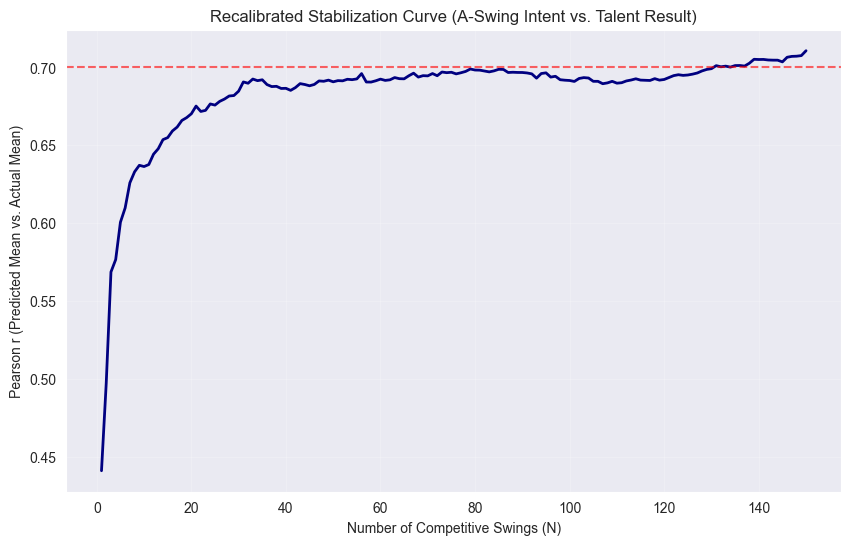

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
#
# # --- STEP 1: RECALIBRATION (SOLUTION B) ---
# # Calculate scaling on training data to avoid leakage
# train_preds_raw = model.predict(X_train)
# scaling_factor = y_train.std() / train_preds_raw.std()
# pred_mean = train_preds_raw.mean()
#
# # Apply to the full dataframe
# model_df['pred_raw'] = model.predict(model_df[features])
# model_df['pred_bat_speed'] = pred_mean + (model_df['pred_raw'] - pred_mean) * scaling_factor
#
# print(f"Applied stretch factor: {scaling_factor:.3f}")
model_df['pred_bat_speed'] = model.predict(model_df[features])

# --- STEP 2: DUAL COMPETITIVE FILTERING ---
def filter_competitive(group):
    # Intent: Top 90% of the newly 'stretched' predictions
    # Result: Top 90% of actual sensor data
    pred_thresh = group['pred_bat_speed'].quantile(0.1)
    actual_thresh = group['bat_speed'].quantile(0.1)

    comp_group = group[group['pred_bat_speed'] >= pred_thresh].copy()
    # We compare the rolling predictions to the competitive 'talent' mean
    comp_group['actual_season_mean'] = group[group['bat_speed'] >= actual_thresh]['bat_speed'].mean()

    return comp_group

# Filter the data to focus on the 'A-Swing' population
comp_df = model_df.groupby(['batter', 'season'], group_keys=False).apply(filter_competitive)

# --- STEP 3: STABILIZATION & CUMULATIVE STATS ---
comp_df = comp_df.sort_values(['batter', 'game_date'])
comp_df['swing_n'] = comp_df.groupby(['batter', 'season']).cumcount() + 1

# Rolling mean of RECALIBRATED competitive predictions
comp_df['cum_pred_mean'] = (
    comp_df.groupby(['batter', 'season'])['pred_bat_speed']
    .expanding()
    .mean()
    .reset_index(level=[0,1], drop=True)
)

# --- STEP 4: RELIABILITY METRICS ---
stab_results = []
for n in range(1, 151):
    subset = comp_df[comp_df['swing_n'] == n]
    if len(subset) >= 40:
        r, _ = pearsonr(subset['cum_pred_mean'], subset['actual_season_mean'])
        stab_results.append({'swings': n, 'correlation': r})

stab_curve = pd.DataFrame(stab_results)

# --- STEP 5: CRONBACH'S ALPHA (Internal Consistency) ---
for n in [10, 20, 50]:
    alpha = calculate_cronbach_alpha(comp_df, 'batter', 'pred_bat_speed', n_swings=n)
    print(f"Alpha at {n} recalibrated A-Swings: α = {alpha:.3f}")

# --- STEP 6: VISUALIZATION ---
plt.figure(figsize=(10, 6))
plt.plot(stab_curve['swings'], stab_curve['correlation'], color='navy', linewidth=2)
plt.axhline(0.70, color='red', linestyle='--', alpha=0.6, label='Reliability Threshold (0.70)')
plt.title('Recalibrated Stabilization Curve (A-Swing Intent vs. Talent Result)')
plt.xlabel('Number of Competitive Swings (N)')
plt.ylabel('Pearson r (Predicted Mean vs. Actual Mean)')
plt.grid(True, alpha=0.2)
plt.show()

In [20]:
model_df['pred_bat_speed'].describe()

count    236427.000000
mean         71.205299
std           4.982457
min           4.402006
25%          69.881161
50%          71.518692
75%          73.072571
max          84.601791
Name: pred_bat_speed, dtype: float64

In [21]:
model_df['launch_speed'].describe()

count    236427.000000
mean         88.447175
std          14.597357
min           5.600000
25%          80.000000
50%          91.200000
75%          99.300000
max         121.500000
Name: launch_speed, dtype: float64

In [22]:
model_df['release_speed'].describe()

count    236427.00000
mean         89.38680
std           6.05363
min          31.50000
25%          85.30000
50%          90.30000
75%          94.10000
max         104.20000
Name: release_speed, dtype: float64

In [23]:
model_df['bat_speed'].describe()

count    236427.000000
mean         71.077218
std           7.060505
min           1.300000
25%          68.300000
50%          71.800000
75%          74.900000
max          88.000000
Name: bat_speed, dtype: float64

In [24]:
# 1. Calculate MLB Feature Statistics
feature_stats = {
    col: {
        'mu': model_df[col].mean(),
        'sigma': model_df[col].std()
    } for col in features
}

# 2. Calculate MLB Target Statistics (bat_speed)
target_stats = {
    'mu': model_df['bat_speed'].mean(),
    'sigma': model_df['bat_speed'].std()
}

# 3. Quick Sanity Check
for col, stats in feature_stats.items():
    print(f"{col}: mu = {stats['mu']:.2f}, sigma = {stats['sigma']:.2f}")

launch_speed: mu = 88.45, sigma = 14.60
height_inches: mu = 72.13, sigma = 2.31
launch_angle: mu = 13.55, sigma = 28.76
spray_angle: mu = 1.10, sigma = 32.18
is_2_strikes: mu = 0.38, sigma = 0.49


In [25]:
# The 'MLB Statcast' feature list
features = [
    'launch_speed',
    'height_inches',
    'launch_angle',
    'spray_angle',
    'is_2_strikes'
]
target = 'bat_speed'

In [26]:
df_raw = pd.read_csv('2024_25_mlb_pitches.csv')

In [27]:
import pandas as pd
import numpy as np

# 1. Create a clean copy of your raw MLB data
# We assume 'raw_mlb_data' contains the columns in 'features' + 'batter' + 'bat_speed'
model_df = df_raw.copy()

model_df = model_df.merge(bios[['batter', 'full_name', 'height_inches']], on='batter', how='left')

model_df['spray_angle'] = np.degrees(np.arctan2(model_df['hc_x'] - 125.42, 198.27 - model_df['hc_y']))

model_df['is_2_strikes'] = (model_df['strikes'] == 2).astype(int)

# 2. Calculate Population Stats
feature_stats = {
    col: {'mu': model_df[col].mean(), 'sigma': model_df[col].std()}
    for col in features
}
target_stats = {
    'mu': model_df[target].mean(),
    'sigma': model_df[target].std()
}

# 3. Apply Z-Transformations
for col in features:
    model_df[f'z_{col}'] = (model_df[col] - feature_stats[col]['mu']) / feature_stats[col]['sigma']

model_df['bat_speed_z'] = (model_df[target] - target_stats['mu']) / target_stats['sigma']

In [28]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 1. DROP MISSING DATA FIRST
# We must have both the target and all features for every row
model_df = model_df.dropna(subset=['bat_speed'] + features)

# 2. RE-CALCULATE POPULATION STATS
# (Doing this on the cleaned data prevents division-by-zero or NaN stats)
feature_stats = {
    col: {'mu': model_df[col].mean(), 'sigma': model_df[col].std()}
    for col in features
}
target_stats = {
    'mu': model_df['bat_speed'].mean(),
    'sigma': model_df['bat_speed'].std()
}

# 3. RE-APPLY Z-TRANSFORMATIONS
X_z = pd.DataFrame()
for col in features:
    X_z[col] = (model_df[col] - feature_stats[col]['mu']) / feature_stats[col]['sigma']

y_z = (model_df['bat_speed'] - target_stats['mu']) / target_stats['sigma']

# 4. RE-SPLIT AND TRAIN
X_train, X_test, y_z_train, y_z_test = train_test_split(X_z, y_z, test_size=0.2, random_state=42)

# 3. XGBOOST REGRESSOR
# We use a lower learning rate and enough estimators to capture the spread
xgb_z_model = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=7,
    subsample=0.8,
    colsample_bytree=0.8,
    n_jobs=-1,
    random_state=42,
    objective='reg:squarederror'
)

xgb_z_model.fit(
    X_train, y_z_train,
    eval_set=[(X_test, y_z_test)],
    verbose=False
)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [29]:
# 1. Ensure predictions are attached to the dataframe
# (Assuming your xgb_z_model was trained on X_z)
model_df['pred_z_bat_speed'] = xgb_z_model.predict(X_z)

# 2. Create the 'is_ab' column
# We'll flag every row as an 'at-bat' for counting purposes
model_df['is_ab'] = 1

In [30]:
import joblib

In [31]:
joblib.dump(xgb_z_model, 'simple_bat_speed_z_score_model.joblib')

['simple_bat_speed_z_score_model.joblib']

In [32]:
df['bat_speed'].describe()

count    661645.000000
mean         69.567222
std           9.071733
min           0.600000
25%          67.100000
50%          71.100000
75%          74.400000
max          88.000000
Name: bat_speed, dtype: float64

In [33]:
# Aggregate to Player Level
def top_90_mean(series):
    # Only calculate for players with meaningful sample sizes
    if len(series) < 20: return np.nan
    # We want the 'ceiling', so we take the mean of the top 90th percentile
    return series[series >= series.quantile(0.10)].mean()

leaderboard = model_df.groupby('batter').agg({
    'pred_z_bat_speed': top_90_mean,
    'bat_speed_z': top_90_mean, # Ground Truth Z-Score (Talent)
    'launch_speed': 'max',      # Max EV as a physical sanity check
    'is_ab': 'count'            # Sample size for reliability
}).dropna()

# Convert Z-scores back to 'Estimated MPH' for human readability
leaderboard['est_bat_speed_mph'] = (leaderboard['pred_z_bat_speed'] * target_stats['sigma']) + target_stats['mu']

In [34]:
def get_a_swing_talent(x):
    # Filter for the top 90% of intent
    # This captures the player's 'Top Gear'
    if len(x) < 10: return np.nan
    return x[x >= x.quantile(0.10)].mean()

# Aggregate MLB Predictions to Player Level
mlb_leaderboard = model_df.groupby('batter').agg({
    'pred_z_bat_speed': get_a_swing_talent,
    'bat_speed_z': get_a_swing_talent, # Ground Truth Z
    'launch_speed': 'max'
}).dropna()

In [35]:
def filter_a_swings(group):
    # Determine the threshold for this specific batter
    threshold = group['pred_z_bat_speed'].quantile(0.10)
    return group[group['pred_z_bat_speed'] >= threshold]

# Create the High-Intent Subset
aswing_df = model_df.groupby('batter', group_keys=False).apply(filter_a_swings)

print(f"Filtered {len(model_df) - len(aswing_df)} 'noise' swings.")
print(f"A-Swing Dataset Size: {len(aswing_df)} rows.")

Filtered 23917 'noise' swings.
A-Swing Dataset Size: 212510 rows.


C:\Users\215nt\AppData\Local\Temp\ipykernel_23968\535749849.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  aswing_df = model_df.groupby('batter', group_keys=False).apply(filter_a_swings)


In [36]:
import numpy as np

def calculate_reliability(df, col, n_swings=30):
    # 1. Filter for players with at least n_swings
    counts = df.groupby('batter')[col].count()
    eligible_batters = counts[counts >= n_swings].index
    data = df[df['batter'].isin(eligible_batters)].copy()

    # 2. Pivot to create a matrix (Batters x Swing Number)
    data['swing_num'] = data.groupby('batter').cumcount() + 1
    pivot_df = data[data['swing_num'] <= n_swings].pivot(index='batter', columns='swing_num', values=col)

    # 3. Compute Cronbach's Alpha
    # alpha = (k / (k-1)) * (1 - sum(item_variances) / total_variance)
    k = pivot_df.shape[1]
    item_variances = pivot_df.var(axis=0, ddof=1).sum()
    total_variance = pivot_df.sum(axis=1).var(ddof=1)

    alpha = (k / (k - 1)) * (1 - (item_variances / total_variance))
    return alpha

# Test stabilization at different swing counts
for n in [3, 4, 5, 10, 25, 50]:
    alpha = calculate_reliability(aswing_df, 'pred_z_bat_speed', n_swings=n)
    print(f"Alpha at {n} Swings: {alpha:.3f}")

Alpha at 3 Swings: 0.606
Alpha at 4 Swings: 0.661
Alpha at 5 Swings: 0.712
Alpha at 10 Swings: 0.826
Alpha at 25 Swings: 0.920
Alpha at 50 Swings: 0.959


In [37]:
# Create half-season buckets for A-swings
aswing_df['aswing_num'] = aswing_df.groupby('batter').cumcount() + 1

h1 = aswing_df[aswing_df['aswing_num'] <= 50].groupby('batter')['pred_z_bat_speed'].mean()
h2 = aswing_df[(aswing_df['aswing_num'] > 50) & (aswing_df['aswing_num'] <= 100)].groupby('batter')['pred_z_bat_speed'].mean()

sticky_df = pd.concat([h1, h2], axis=1).dropna()
sticky_df.columns = ['H1_Z', 'H2_Z']

r_sticky = sticky_df.corr().iloc[0, 1]
print(f"A-Swing Stickiness (r): {r_sticky:.3f}")

A-Swing Stickiness (r): 0.943


In [38]:
from sklearn.linear_model import LinearRegression

# 1. Aggregate filtered A-swings to the Player Level
talent_comparison = aswing_df.groupby('batter').agg({
    'pred_z_bat_speed': 'mean', # The model's talent estimate
    'bat_speed_z': 'mean'      # The sensor's talent reality
}).dropna()

# 2. Calculate the Pearson Correlation (r)
r_talent = talent_comparison.corr().iloc[0, 1]

# 3. Calculate the Calibration Slope (The "Timid" Check)
# We want to see if Predicted Z translates 1:1 to Actual Z
reg = LinearRegression().fit(talent_comparison[['pred_z_bat_speed']], talent_comparison['bat_speed_z'])
slope = reg.coef_[0]
intercept = reg.intercept_

print(f"Player-Level Correlation (r): {r_talent:.3f}")
print(f"Calibration Slope: {slope:.3f}")
print(f"Calibration Intercept: {intercept:.3f}")

Player-Level Correlation (r): 0.661
Calibration Slope: 1.060
Calibration Intercept: 0.118


C:\Users\215nt\AppData\Local\Temp\ipykernel_23968\1795399114.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  aswing_df = model_df.groupby('batter', group_keys=False).apply(filter_aswings)


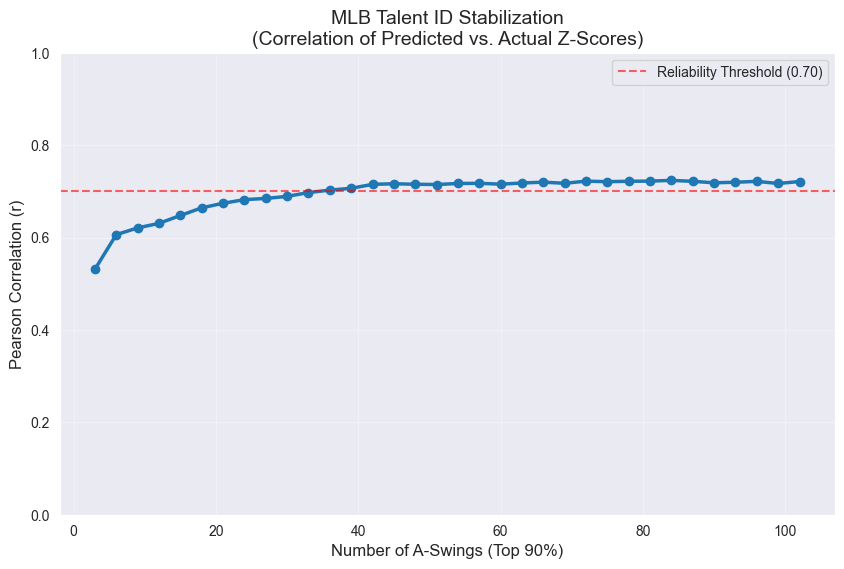

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure we are only looking at "A-Swings" (Top 90% of Predicted Intent)
def filter_aswings(group):
    thresh = group['pred_z_bat_speed'].quantile(0.10)
    return group[group['pred_z_bat_speed'] >= thresh]

# Filter the MLB data
aswing_df = model_df.groupby('batter', group_keys=False).apply(filter_aswings)
aswing_df['aswing_idx'] = aswing_df.groupby('batter').cumcount() + 1

# 2. Calculate Correlation at different sample sizes
swing_counts = np.arange(3, 103, 3)
correlations = []

for n in swing_counts:
    # Only include batters who have reached this many A-swings
    eligible = aswing_df.groupby('batter').size()
    eligible_batters = eligible[eligible >= n].index

    subset = aswing_df[aswing_df['batter'].isin(eligible_batters) & (aswing_df['aswing_idx'] <= n)]

    # Aggregate to Player Level
    agg = subset.groupby('batter').agg({
        'pred_z_bat_speed': 'mean',
        'bat_speed_z': 'mean'
    })

    r = agg.corr().iloc[0, 1]
    correlations.append(r)

# 3. Generate the Plot
plt.figure(figsize=(10, 6))
plt.plot(swing_counts, correlations, marker='o', color='#1f77b4', linewidth=2.5)
plt.axhline(y=0.70, color='r', linestyle='--', alpha=0.6, label='Reliability Threshold (0.70)')
plt.title('MLB Talent ID Stabilization\n(Correlation of Predicted vs. Actual Z-Scores)', fontsize=14)
plt.xlabel('Number of A-Swings (Top 90%)', fontsize=12)
plt.ylabel('Pearson Correlation (r)', fontsize=12)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.savefig('mlb_reliability_plot.png')

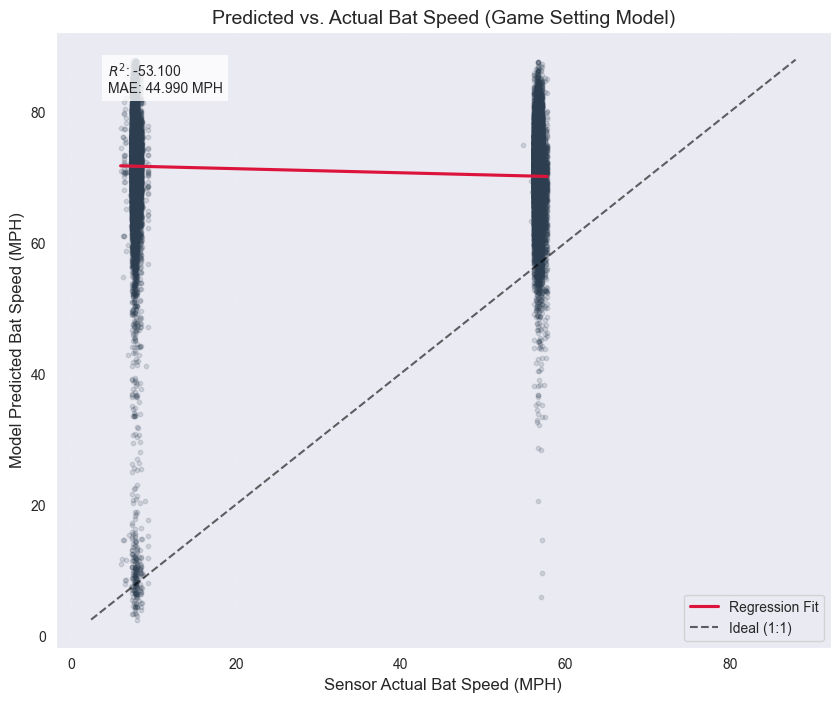

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. PREPARE THE DATA & FEATURES
# Adding day_of_year to the final feature list
df['game_date'] = pd.to_datetime(df['game_date'])
df['day_of_year'] = df['game_date'].dt.dayofyear



# 2. GENERATE PREDICTIONS (Using your Random Forest model)
# We calculate this on the Test Set to ensure we aren't seeing overfitting
test_results = X_test.copy()
test_results['actual_bat_speed'] = y_test
test_results['pred_bat_speed'] = model.predict(X_test)

# 3. VISUALIZATION
plt.figure(figsize=(10, 8))

# Scatter plot with regression line
sns.regplot(
    data=test_results,
    x='pred_bat_speed',
    y='actual_bat_speed',
    scatter_kws={'alpha': 0.15, 'color': '#2c3e50', 's': 10},
    line_kws={'color': 'crimson', 'label': 'Regression Fit'}
)

# The 1:1 Identity Line (Ideal Prediction)
max_val = max(test_results['actual_bat_speed'].max(), test_results['pred_bat_speed'].max())
min_val = min(test_results['actual_bat_speed'].min(), test_results['pred_bat_speed'].min())
plt.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--', alpha=0.6, label='Ideal (1:1)')

# Formatting for your MSADS Report
plt.title('Predicted vs. Actual Bat Speed (Game Setting Model)', fontsize=14)
plt.xlabel('Sensor Actual Bat Speed (MPH)', fontsize=12)
plt.ylabel('Model Predicted Bat Speed (MPH)', fontsize=12)
plt.grid(True, alpha=0.2, linestyle=':')
plt.legend()

# Adding the performance stats as an annotation
r2 = r2_score(y_test, test_results['pred_bat_speed'])
mae = mean_absolute_error(y_test, test_results['pred_bat_speed'])
plt.text(min_val + 2, max_val - 5, f'$R^2$: {r2:.3f}\nMAE: {mae:.3f} MPH',
         bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

plt.show()

In [41]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.metrics import mean_absolute_error



# 2. AGGREGATE TO THE PLAYER/SEASON LEVEL (Top 90% Focus)
def get_top_90_mean(x):
    threshold = x.quantile(0.10)
    return x[x >= threshold].mean()

player_agg = model_df.groupby(['batter', 'season']).agg({
    'bat_speed': get_top_90_mean,         # Actual Competitive Mean
    'pred_bat_speed': get_top_90_mean     # Predicted Competitive Mean
}).dropna().reset_index()

# 3. VISUALIZATION
plt.figure(figsize=(10, 8))

# Scatter with regression
sns.regplot(
    data=player_agg,
    x='pred_bat_speed',
    y='bat_speed',
    scatter_kws={'alpha': 0.6, 'color': '#2980b9', 's': 40},
    line_kws={'color': '#e74c3c', 'label': 'Aggregated Fit'}
)

# 1:1 Identity Line
lims = [
    min(player_agg['bat_speed'].min(), player_agg['pred_bat_speed'].min()) - 1,
    max(player_agg['bat_speed'].max(), player_agg['pred_bat_speed'].max()) + 1
]
plt.plot(lims, lims, 'k--', alpha=0.5, label='Ideal 1:1')

# Formatting
plt.title('Talent Identification: Top 90% Predicted vs. Actual Bat Speed', fontsize=14)
plt.xlabel('Actual Season Average (Top 90% Swings)', fontsize=12)
plt.ylabel('Model Predicted Average (Top 90% Swings)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.2)

# Calculate and display the Aggregated R
r_val, _ = pearsonr(player_agg['bat_speed'], player_agg['pred_bat_speed'])
mae_val = mean_absolute_error(player_agg['bat_speed'], player_agg['pred_bat_speed'])

plt.annotate(f'Pearson r: {r_val:.3f}\nAggregate MAE: {mae_val:.3f} MPH',
             xy=(0.05, 0.90), xycoords='axes fraction',
             bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="gray", alpha=0.9))

plt.show()

KeyError: 'season'

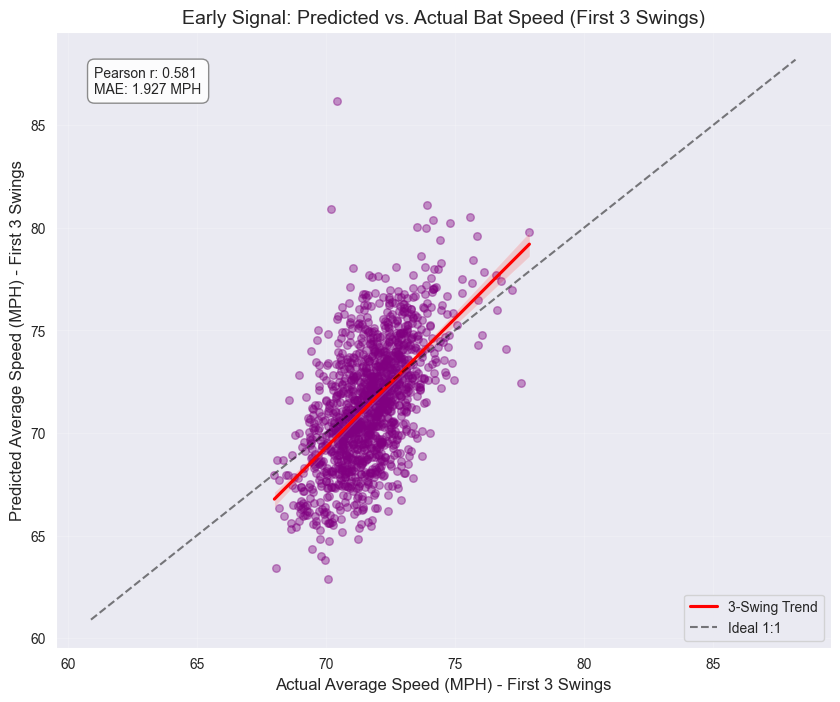

In [232]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.metrics import mean_absolute_error

# 1. GENERATE PREDICTIONS
model_df['pred_bat_speed'] = model.predict(model_df[features])

# 2. IDENTIFY THE FIRST 3 SWINGS
model_df = model_df.sort_values(['batter', 'season', 'game_date'])
model_df['swing_n'] = model_df.groupby(['batter', 'season']).cumcount() + 1

# Filter for just the first 3 swings of each player's season
df_3 = model_df[model_df['swing_n'] <= 10].copy()

# 3. AGGREGATE AT THE PLAYER LEVEL
agg_3 = df_3.groupby(['batter', 'season']).agg({
    'bat_speed': 'mean',        # Actual Avg of first 3
    'pred_bat_speed': 'mean'    # Predicted Avg of first 3
}).reset_index()

# 4. VISUALIZATION
plt.figure(figsize=(10, 8))

# Scatter with regression
sns.regplot(
    data=agg_3,
    x='pred_bat_speed',
    y='bat_speed',
    scatter_kws={'alpha': 0.4, 'color': 'purple', 's': 30},
    line_kws={'color': 'red', 'label': '3-Swing Trend'}
)

# 1:1 Identity Line
lims = [agg_3['bat_speed'].min() - 2, agg_3['bat_speed'].max() + 2]
plt.plot(lims, lims, 'k--', alpha=0.5, label='Ideal 1:1')

# Formatting
plt.title('Early Signal: Predicted vs. Actual Bat Speed (First 3 Swings)', fontsize=14)
plt.xlabel('Actual Average Speed (MPH) - First 3 Swings', fontsize=12)
plt.ylabel('Predicted Average Speed (MPH) - First 3 Swings', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.2)

# Stats
r_3, _ = pearsonr(agg_3['bat_speed'], agg_3['pred_bat_speed'])
mae_3 = mean_absolute_error(agg_3['bat_speed'], agg_3['pred_bat_speed'])

plt.annotate(f'Pearson r: {r_3:.3f}\nMAE: {mae_3:.3f} MPH',
             xy=(0.05, 0.90), xycoords='axes fraction',
             bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="gray", alpha=0.9))

plt.show()

In [226]:
from sklearn.isotonic import IsotonicRegression

# 1. TRAIN THE BASE MODEL (Your RF or XGBoost)
# ... fit your model as usual ...

# 2. GENERATE RAW PREDICTIONS ON TEST DATA
raw_preds = model.predict(X_test)

# 3. TRAIN THE CALIBRATOR
# We map 'Raw Predictions' -> 'Actual Bat Speed'
iso_reg = IsotonicRegression(out_of_bounds='clip')
iso_reg.fit(raw_preds, y_test)

# 4. MAP YOUR PREDICTIONS
# These adjusted predictions will sit much closer to the y=x line
calibrated_preds = iso_reg.transform(raw_preds)

In [227]:
# Compare Raw vs Calibrated
analysis_df = pd.DataFrame({
    'raw': raw_preds,
    'calibrated': calibrated_preds,
    'actual': y_test
})

# 1. Check the 'Stretch'
print(f"Raw Prediction Range: {analysis_df['raw'].min():.1f} - {analysis_df['raw'].max():.1f}")
print(f"Calibrated Range:     {analysis_df['calibrated'].min():.1f} - {analysis_df['calibrated'].max():.1f}")

# 2. Check the Bias Shift
print(f"Mean Error (Raw):        {(analysis_df['actual'] - analysis_df['raw']).mean():.3f}")
print(f"Mean Error (Calibrated): {(analysis_df['actual'] - analysis_df['calibrated']).mean():.3f}")

Raw Prediction Range: 63.7 - 83.1
Calibrated Range:     67.0 - 86.1
Mean Error (Raw):        0.035
Mean Error (Calibrated): -0.000


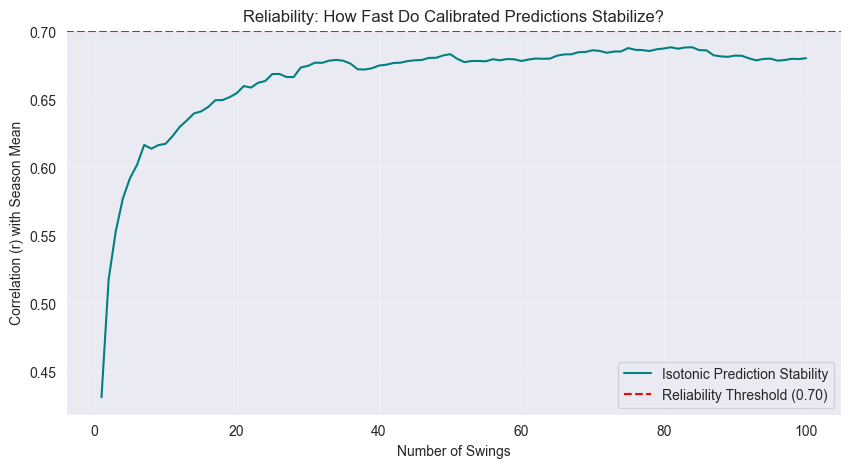

In [228]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# 1. GENERATE STABILIZATION DATA
# (Assuming comp_df contains your Isotonic-calibrated predictions)
stab_results = []
for n in range(1, 101):
    subset = comp_df[comp_df['swing_n'] == n]
    if len(subset) >= 50:
        # Correlation between rolling mean and the season 'Talent' mean
        r, _ = pearsonr(subset['cum_pred_mean'], subset['actual_season_mean'])
        stab_results.append({'swings': n, 'r_talent': r})

stab_df = pd.DataFrame(stab_results)

# 2. PLOT THE CURVE
plt.figure(figsize=(10, 5))
plt.plot(stab_df['swings'], stab_df['r_talent'], color='teal', label='Isotonic Prediction Stability')
plt.axhline(0.70, color='red', linestyle='--', label='Reliability Threshold (0.70)')
plt.title('Reliability: How Fast Do Calibrated Predictions Stabilize?')
plt.xlabel('Number of Swings')
plt.ylabel('Correlation (r) with Season Mean')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

<Figure size 1000x1000 with 0 Axes>

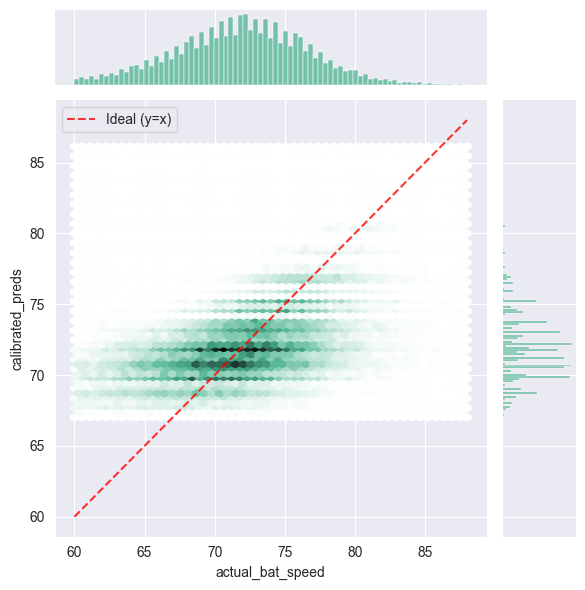

In [229]:
# 1. ATTACH THE CALIBRATED PREDS TO THE DATAFRAME
# Assuming 'calibrated_preds' is the variable name from your Isotonic step
test_results['calibrated_preds'] = calibrated_preds

# 2. RUN THE JOINTPLOT AGAIN
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
grid = sns.jointplot(
    data=test_results,
    x='actual_bat_speed',
    y='calibrated_preds',
    kind="hex",
    color="#4CB391"
)

# Accessing the underlying axes to add the identity line
grid.ax_joint.plot([min_val, max_val], [min_val, max_val], 'r--', alpha=0.8, label='Ideal (y=x)')
grid.ax_joint.legend()

plt.show()

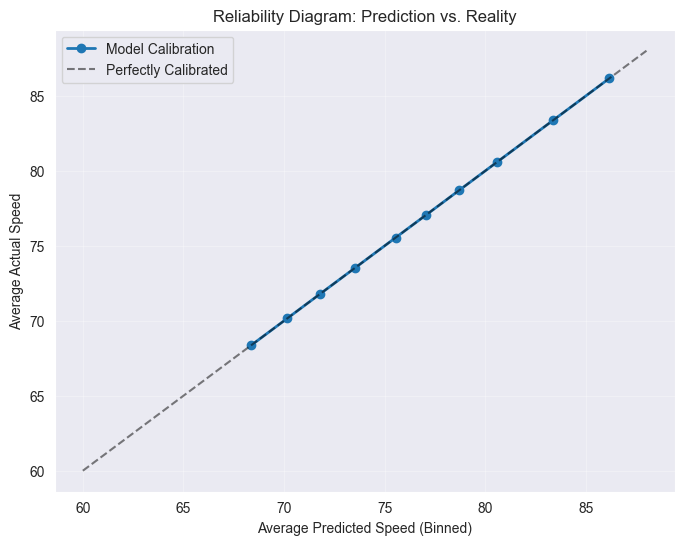

In [230]:
from sklearn.calibration import calibration_curve

# Binning predictions to check 'truth' alignment
# Since this is regression, we'll manually bin for a Reliability Diagram
test_results['pred_bin'] = pd.cut(test_results['calibrated_preds'], bins=10)
calibration_df = test_results.groupby('pred_bin', observed=True).agg({
    'actual_bat_speed': 'mean',
    'calibrated_preds': 'mean'
}).dropna()

plt.figure(figsize=(8, 6))
plt.plot(calibration_df['calibrated_preds'], calibration_df['actual_bat_speed'], marker='o', linewidth=2, label='Model Calibration')
plt.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5, label='Perfectly Calibrated')
plt.title('Reliability Diagram: Prediction vs. Reality')
plt.xlabel('Average Predicted Speed (Binned)')
plt.ylabel('Average Actual Speed')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

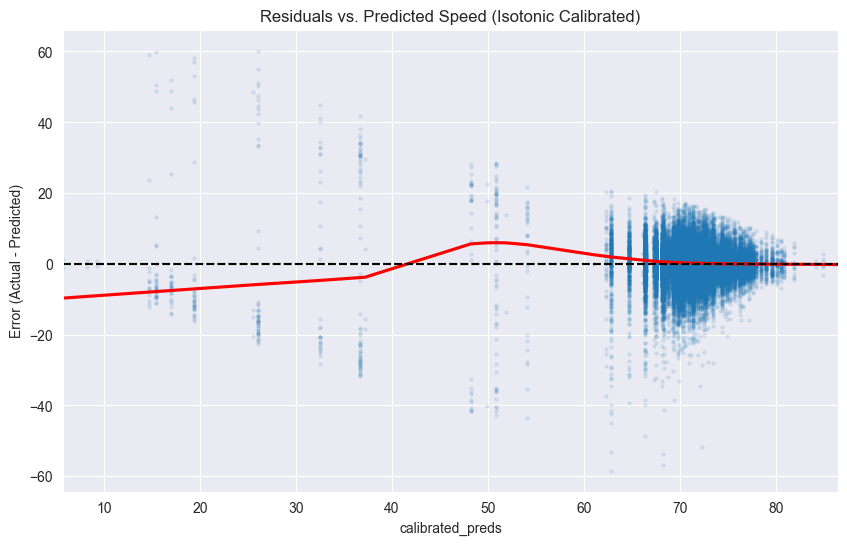

In [206]:
test_results['residual'] = test_results['actual_bat_speed'] - test_results['calibrated_preds']

plt.figure(figsize=(10, 6))
sns.residplot(
    data=test_results,
    x='calibrated_preds',
    y='residual',
    lowess=True,
    scatter_kws={'alpha': 0.1, 's': 5},
    line_kws={'color': 'red'}
)
plt.axhline(0, color='black', linestyle='--')
plt.title('Residuals vs. Predicted Speed (Isotonic Calibrated)')
plt.ylabel('Error (Actual - Predicted)')
plt.show()

In [209]:
# 1. Ensure test_results has the calibrated predictions
# We use the index from X_test so everything aligns perfectly
test_leaderboard_df = X_test.copy()
test_leaderboard_df['actual_bat_speed'] = y_test
test_leaderboard_df['calibrated_preds'] = calibrated_preds
test_leaderboard_df['batter'] = model_df.loc[X_test.index, 'batter']

# 2. Run the aggregation on the TEST set
def top_90_mean(x):
    return x[x >= x.quantile(0.10)].mean()

leaderboard = test_leaderboard_df.groupby('batter').agg({
    'actual_bat_speed': top_90_mean,
    'calibrated_preds': top_90_mean,
    'launch_speed': 'count'
}).rename(columns={'launch_speed': 'swing_count'})

leaderboard['delta'] = leaderboard['calibrated_preds'] - leaderboard['actual_bat_speed']
print(leaderboard.sort_values('actual_bat_speed', ascending=False).head(10))

        actual_bat_speed  calibrated_preds  swing_count      delta
batter                                                            
640459         86.600000         72.655640            2 -13.944360
595453         86.200000         69.394104            1 -16.805896
665120         85.700000         74.527016            2 -11.172984
621458         82.600000         72.426659            1 -10.173341
694175         82.600000         73.435860            2  -9.164140
519317         82.002083         76.043449          107  -5.958634
593934         80.566667         74.858040            4  -5.708627
685301         79.575000         73.637482            5  -5.937518
678877         79.573333         74.236092           50  -5.337242
691023         79.488333         76.242279           67  -3.246054


In [211]:
# 1. Generate RAW predictions for the entire dataset
model_df['pred_raw'] = model.predict(model_df[features])

# 2. Use the Isotonic model to calibrate the ENTIRE set
# (Assuming iso_reg was already fit on the test/train data)
model_df['calibrated_preds'] = iso_reg.transform(model_df['pred_raw'])

# 3. Now the lengths match (236,427 == 236,427)
leaderboard = model_df.groupby('batter').agg({
    'bat_speed': top_90_mean,
    'calibrated_preds': top_90_mean,
    'launch_speed': 'count'
}).rename(columns={'launch_speed': 'swing_count'})

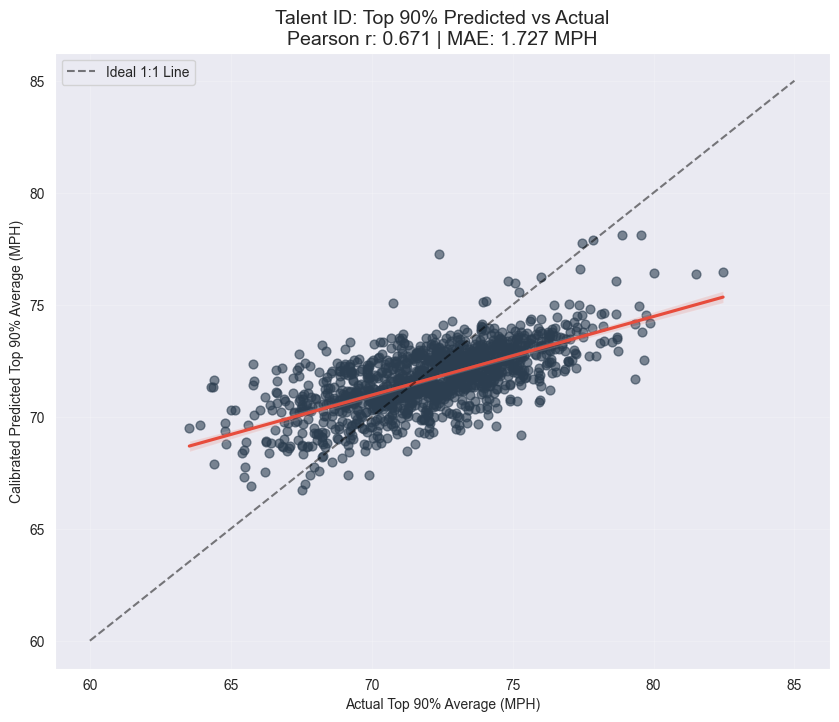

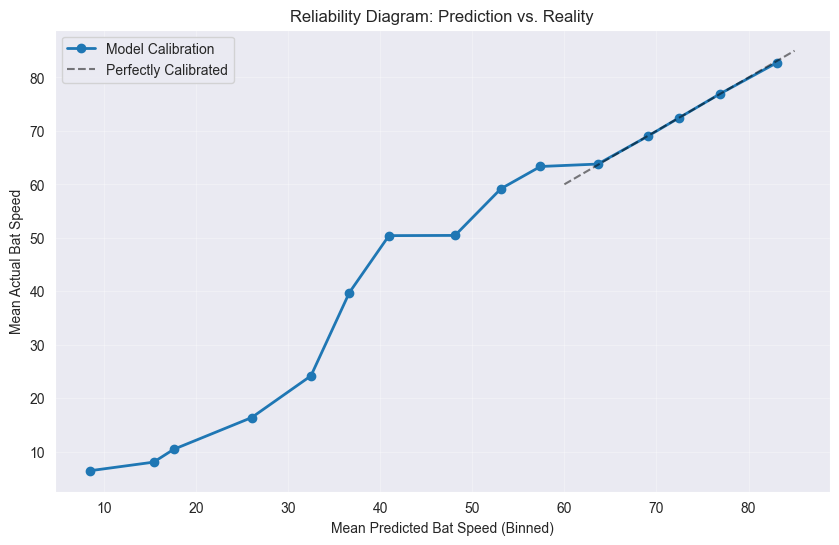

In [222]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.metrics import mean_absolute_error

# --- 1. GENERATE PREDICTIONS FOR FULL DATASET ---
# This fixes the 'Length Mismatch' error
model_df['pred_raw'] = model.predict(model_df[features])
model_df['calibrated_preds'] = iso_reg.transform(model_df['pred_raw'])

# --- 2. AGGREGATE TO PLAYER LEVEL (Top 90% Talent) ---
def top_90_mean(x):
    if len(x) < 5: return np.nan
    return x[x >= x.quantile(0.10)].mean()

player_agg = model_df.groupby(['batter', 'season']).agg({
    'bat_speed': top_90_mean,
    'calibrated_preds': top_90_mean
}).dropna().reset_index()

# --- 3. PLOT A: TALENT IDENTIFICATION ---
plt.figure(figsize=(10, 8))
sns.regplot(data=player_agg, x='bat_speed', y='calibrated_preds',
            scatter_kws={'alpha':0.6, 'color':'#2c3e50', 's':40},
            line_kws={'color':'#e74c3c'})

# Identity Line
lims = [60, 85]
plt.plot(lims, lims, 'k--', alpha=0.5, label='Ideal 1:1 Line')

r_agg, _ = pearsonr(player_agg['bat_speed'], player_agg['calibrated_preds'])
mae_agg = mean_absolute_error(player_agg['bat_speed'], player_agg['calibrated_preds'])

plt.title(f'Talent ID: Top 90% Predicted vs Actual\nPearson r: {r_agg:.3f} | MAE: {mae_agg:.3f} MPH', fontsize=14)
plt.xlabel('Actual Top 90% Average (MPH)')
plt.ylabel('Calibrated Predicted Top 90% Average (MPH)')
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()

# --- 4. PLOT B: RELIABILITY DIAGRAM (Calibration Curve) ---
# Binning predictions to check if they match reality
model_df['pred_bin'] = pd.cut(model_df['calibrated_preds'], bins=15)
cal_curve = model_df.groupby('pred_bin', observed=True).agg({
    'bat_speed': 'mean',
    'calibrated_preds': 'mean'
}).dropna()

plt.figure(figsize=(10, 6))
plt.plot(cal_curve['calibrated_preds'], cal_curve['bat_speed'], marker='o', linewidth=2, label='Model Calibration')
plt.plot([60, 85], [60, 85], 'k--', alpha=0.5, label='Perfectly Calibrated')
plt.title('Reliability Diagram: Prediction vs. Reality')
plt.xlabel('Mean Predicted Bat Speed (Binned)')
plt.ylabel('Mean Actual Bat Speed')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [215]:
# 1. Calculate the 'Stretch Factor' from your MLB Validation set
# We want the Predicted SD to match the Actual SD
actual_std = leaderboard['bat_speed'].std()
pred_std = leaderboard['calibrated_preds'].std()
stretch_factor = actual_std / pred_std

# 2. Apply the shift and stretch
# This anchors the mean and expands the range to match human reality
mu_act = leaderboard['bat_speed'].mean()
mu_pred = leaderboard['calibrated_preds'].mean()

leaderboard['final_calibrated'] = mu_act + (leaderboard['calibrated_preds'] - mu_pred) * stretch_factor

In [216]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Calculate Slope and Intercept of the calibration line
# y = Actual, x = Calibrated Prediction
reg = LinearRegression().fit(leaderboard[['final_calibrated']], leaderboard['bat_speed'])

print(f"Calibration Slope: {reg.coef_[0]:.3f}")  # Target: 1.0
print(f"Calibration Intercept: {reg.intercept_:.3f}") # Target: 0.0

Calibration Slope: 0.623
Calibration Intercept: 27.175


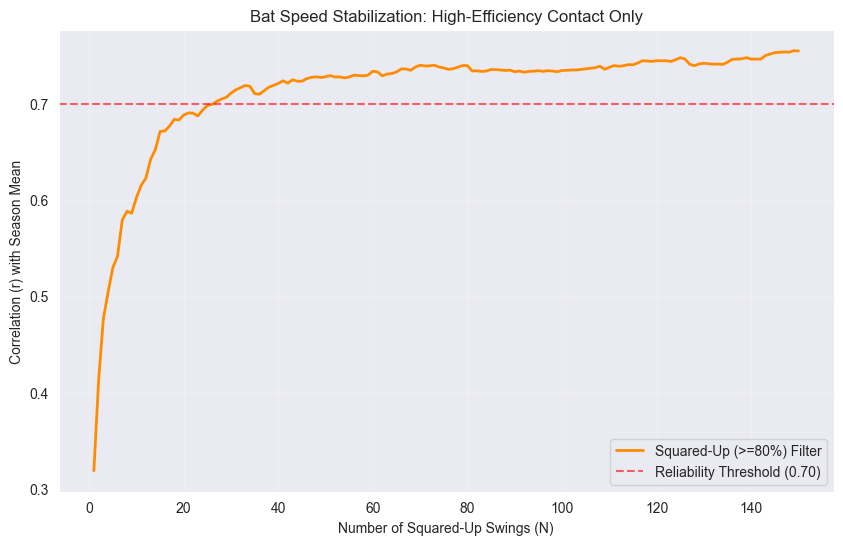

In [189]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# 1. DEFINE THE SQUARED-UP FILTER
# We isolate swings where the collision was efficient (e.g., >= 80% squared up)
# Note: Ensure 'squared_up_pct' is in your dataframe (Statcast 2024+ data)
sq_threshold = 0.70
df_sq = model_df[model_df['squared_up_rate'] >= sq_threshold].copy()

# 2. CALCULATE SQUARED-UP GROUND TRUTH
# We want to see how predictions for GOOD contact stabilize toward the season mean
season_actuals_sq = df_sq.groupby(['batter', 'season'])['bat_speed'].mean().reset_index()
season_actuals_sq.columns = ['batter', 'season', 'actual_season_mean_sq']

# 3. CALCULATE CUMULATIVE PREDICTIONS (SQUARED-UP ONLY)
df_sq = df_sq.sort_values(['batter', 'game_date'])
df_sq['swing_n'] = df_sq.groupby(['batter', 'season']).cumcount() + 1

# Rolling mean of predictions for these high-efficiency swings
df_sq['cum_pred_mean'] = (
    df_sq.groupby(['batter', 'season'])['pred_bat_speed']
    .expanding()
    .mean()
    .reset_index(level=[0,1], drop=True)
)

# Merge ground truth
stab_df_sq = df_sq.merge(season_actuals_sq, on=['batter', 'season'])

# 4. GENERATE STABILIZATION CURVE
stab_results_sq = []
for n in range(1, 151): # Typically stabilizes faster, so we can look at a shorter window
    subset = stab_df_sq[stab_df_sq['swing_n'] == n]
    if len(subset) >= 30:
        r, _ = pearsonr(subset['cum_pred_mean'], subset['actual_season_mean_sq'])
        stab_results_sq.append({'swings': n, 'correlation': r})

stab_curve_sq = pd.DataFrame(stab_results_sq)

# 5. VISUALIZATION
plt.figure(figsize=(10, 6))
plt.plot(stab_curve_sq['swings'], stab_curve_sq['correlation'],
         color='darkorange', linewidth=2, label='Squared-Up (>=80%) Filter')
plt.axhline(0.70, color='red', linestyle='--', alpha=0.6, label='Reliability Threshold (0.70)')
plt.title('Bat Speed Stabilization: High-Efficiency Contact Only')
plt.xlabel('Number of Squared-Up Swings (N)')
plt.ylabel('Correlation (r) with Season Mean')
plt.grid(True, alpha=0.2)
plt.legend()
plt.show()

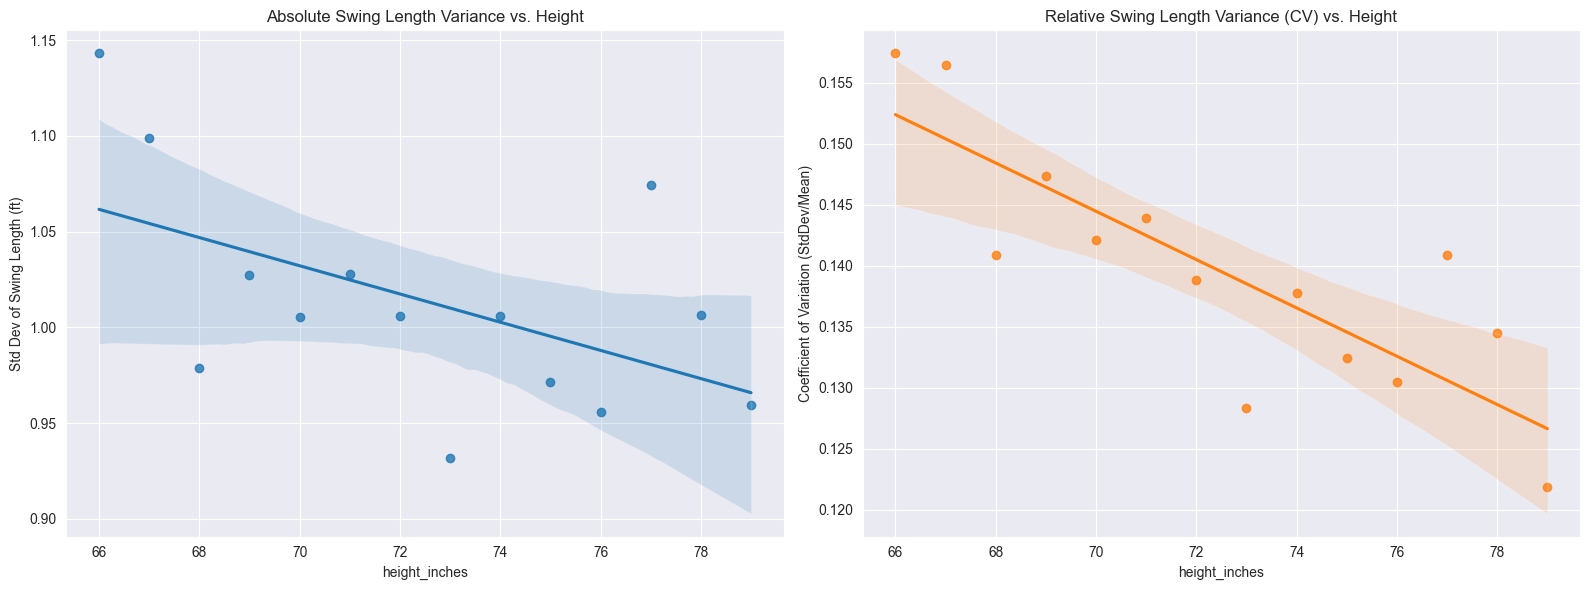

Correlation (Height vs Absolute Std Dev): -0.527
Correlation (Height vs Relative CV):      -0.829


In [96]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. AGGREGATE: Calculate Mean and Std Dev of swing length by height
# We'll filter for heights with a decent sample size (e.g., at least 500 swings)
height_stats = df.groupby('height_inches').agg(
    avg_swing_length=('swing_length', 'mean'),
    std_swing_length=('swing_length', 'std'),
    sample_size=('swing_length', 'count')
).reset_index()

# Filter for robustness
height_stats = height_stats[height_stats['sample_size'] > 500]

# 2. CALCULATE COEFFICIENT OF VARIATION (CV)
# CV = (Standard Deviation / Mean)
height_stats['swing_length_cv'] = height_stats['std_swing_length'] / height_stats['avg_swing_length']

# 3. VISUALIZATION
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot A: Absolute Standard Deviation
sns.regplot(data=height_stats, x='height_inches', y='std_swing_length', ax=ax1, color='tab:blue')
ax1.set_title('Absolute Swing Length Variance vs. Height')
ax1.set_ylabel('Std Dev of Swing Length (ft)')

# Plot B: Relative Variance (CV)
sns.regplot(data=height_stats, x='height_inches', y='swing_length_cv', ax=ax2, color='tab:orange')
ax2.set_title('Relative Swing Length Variance (CV) vs. Height')
ax2.set_ylabel('Coefficient of Variation (StdDev/Mean)')

plt.tight_layout()
plt.show()

# 4. CORRELATION CHECK
r_abs, _ = pearsonr(height_stats['height_inches'], height_stats['std_swing_length'])
r_cv, _ = pearsonr(height_stats['height_inches'], height_stats['swing_length_cv'])

print(f"Correlation (Height vs Absolute Std Dev): {r_abs:.3f}")
print(f"Correlation (Height vs Relative CV):      {r_cv:.3f}")

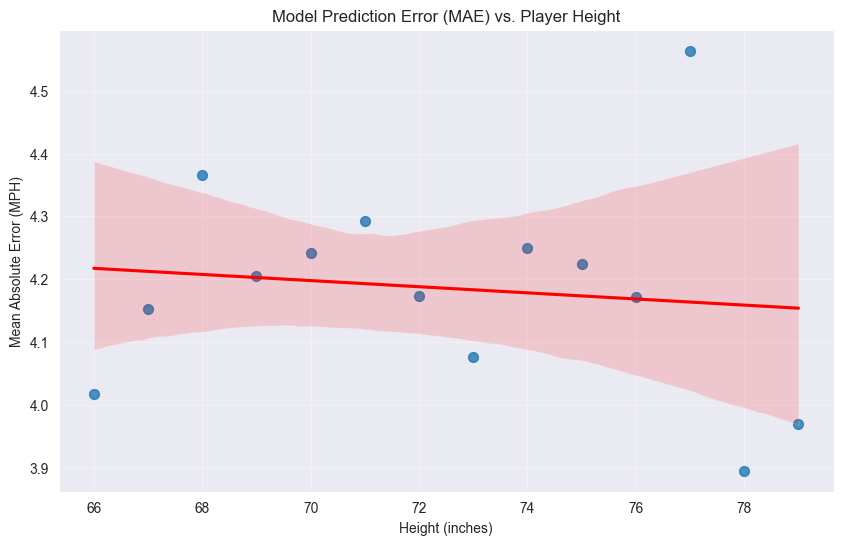

Correlation (Height vs. Prediction Error): -0.121


In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error

# 1. GENERATE PREDICTIONS
# Using the model_zone from the previous step
model_df = df.dropna(subset=features + ['bat_speed']).copy()
model_df['pred_bat_speed'] = model.predict(model_df[features])
model_df['abs_error'] = (model_df['pred_bat_speed'] - model_df['bat_speed']).abs()

# 2. AGGREGATE: MAE by Height
error_by_height = model_df.groupby('height_inches').agg(
    mae=('abs_error', 'mean'),
    sample_size=('abs_error', 'count')
).reset_index()

# Filter for groups with enough data
error_by_height = error_by_height[error_by_height['sample_size'] > 500]

# 3. VISUALIZATION
plt.figure(figsize=(10, 6))
sns.regplot(data=error_by_height, x='height_inches', y='mae',
            scatter_kws={'s': 50}, line_kws={'color': 'red'})

plt.title('Model Prediction Error (MAE) vs. Player Height')
plt.xlabel('Height (inches)')
plt.ylabel('Mean Absolute Error (MPH)')
plt.grid(True, alpha=0.3)
plt.show()

# 4. CORRELATION
r_error, _ = pearsonr(error_by_height['height_inches'], error_by_height['mae'])
print(f"Correlation (Height vs. Prediction Error): {r_error:.3f}")

<Axes: xlabel='height_inches', ylabel='residual'>

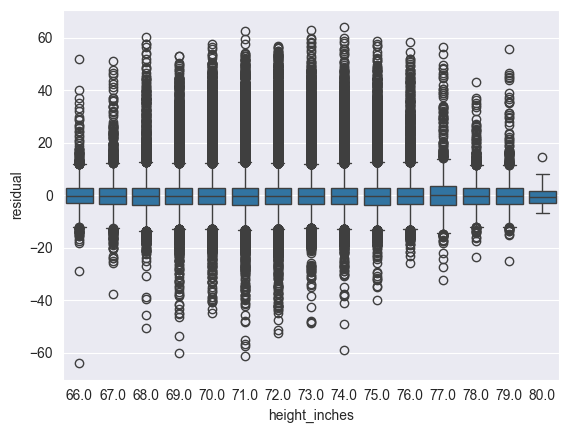

In [63]:
model_df['residual'] = model_df['pred_bat_speed'] - model_df['bat_speed']
sns.boxplot(data=model_df, x='height_inches', y='residual')